# Freight rate prediction assessment

Each row describes a truck shipment, called a load. I predict its shipment price,
`posted_rate`, from the available load features. I sort by date and load ID so that
the time-based evaluation learns from earlier shipments.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / "src/config.py").exists())
sys.path.insert(0, str(ROOT))
from src.analysis import explore_training, check_external, split_summary
from src.features import build_features, clean_data, daily_behaviour
from src.train import cross_validate
from src.run import run_final
from src.config import FEATURES, PARAMS
E = ROOT / "reports/evidence"
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
def show_table(name):
    table = pd.read_csv(E / (name + ".csv"))
    display(table.round(2))
    return table

## Load the data and explore quality

I inspect missing values, duplicates, weight magnitudes, and the price distribution.
Rate per mile means `posted_rate / distance`; the model later multiplies its
rate-per-mile prediction by distance to return dollars.

In [2]:
df = explore_training()
display(df.head())

{
  "rows": 48000,
  "columns": 14,
  "start": "2025-01-01",
  "end": "2025-10-31",
  "duplicate_rows": 0,
  "duplicate_ids": 0,
  "missing_weight": 300,
  "negative_weight": 292,
  "missing_market_index": 374,
  "nonpositive_distance": 0,
  "price_distance_correlation": 0.91,
  "rpm_above_8": 145,
  "rpm_max": 14.13,
  "rpm_median": 2.15,
  "distance_min": 70.0,
  "distance_max": 3439.8
}
quality
              missing
load_id             0
pickup              0
delivery            0
pickup_lat          0
pickup_lon          0
delivery_lat        0
delivery_lon        0
distance            0
equipment           0
weight            300
date                0
market_index      374
quote_signal        0
posted_rate         0

training_description
                count      mean      std       min       25%       50%       75%       max
pickup_lat    48000.0     35.65     4.32     28.36     31.99     35.29     39.41     44.30
pickup_lon    48000.0    -90.93    13.48   -121.70    -98.40    -

training_behaviour
behaviour  flat  follows price  upside down
date                                       
2025-01       0             31            0
2025-02       0             28            0
2025-03       0             31            0
2025-04       0              0           30
2025-05       0              0           31
2025-06       0             30            0
2025-07       0              0           31
2025-08      31              0            0
2025-09       0             30            0
2025-10       0              0           31



training_quote_medians
distance  <=200  200-300  300-450  450-600  600-1000  >1000
date                                                       
2025-01    2.64     2.46     2.29     2.18      2.05   1.90
2025-02    2.73     2.47     2.33     2.20      2.10   1.93
2025-03    2.76     2.61     2.42     2.29      2.17   1.99
2025-04    1.37     1.57     1.71     1.84      1.97   2.14
2025-05    1.31     1.48     1.67     1.79      1.94   2.10
2025-06    2.93     2.71     2.52     2.40      2.28   2.09
2025-07    1.32     1.52     1.70     1.81      1.94   2.10
2025-08    2.04     2.06     2.05     2.04      2.04   2.06
2025-09    2.85     2.61     2.45     2.32      2.20   2.00
2025-10    1.35     1.53     1.71     1.84      1.95   2.13

training_correlation_ranges
                min   max  count
behaviour                       
flat          -0.11  0.15     31
follows price -0.89 -0.72    150
upside down    0.70  0.88    123



training_rpm_medians
distance  <=200  200-300  300-450  450-600  600-1000  >1000
date                                                       
2025-01    2.64     2.46     2.29     2.18      2.05   1.90
2025-02    2.73     2.48     2.32     2.20      2.10   1.92
2025-03    2.76     2.62     2.42     2.29      2.16   1.99
2025-04    2.78     2.58     2.43     2.32      2.17   2.01
2025-05    2.84     2.68     2.48     2.36      2.21   2.05
2025-06    2.94     2.71     2.52     2.41      2.28   2.09
2025-07    2.84     2.64     2.45     2.35      2.21   2.05
2025-08    2.77     2.54     2.36     2.29      2.15   1.98
2025-09    2.86     2.62     2.45     2.31      2.19   2.01
2025-10    2.81     2.62     2.46     2.30      2.20   2.02

{'rows_before': 48000, 'rows_after': 48000, 'negative_after': 0, 'missing_weight_after': 300, 'missing_market_after': 374}


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


- The labeled data has **48,000 rows**, from **2025-01-01** to **2025-10-31**. [Source: training_summary.json]
- There are **300 missing weights**, **292 negative weights**, and **374 missing market-index values**. Duplicate rows and duplicate IDs are both **0**. [Source: training_summary.json]
- The median rate per mile is **$2.15**. The maximum is **$14.13**; extreme labels are retained. [Source: training_summary.json]

All evidence filenames in this notebook refer to `reports/evidence/`. The preceding
cell prints these tables using the shared analysis functions.

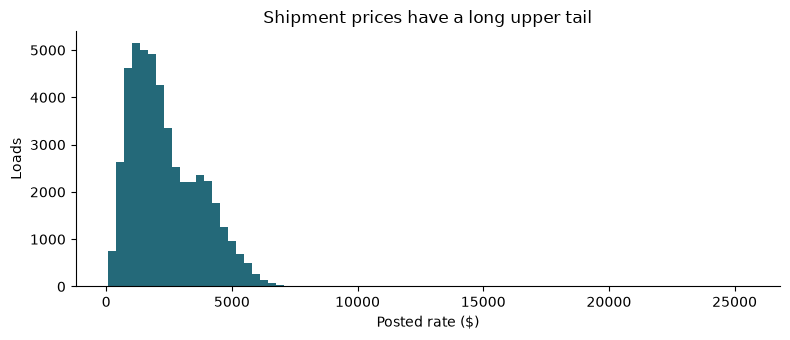

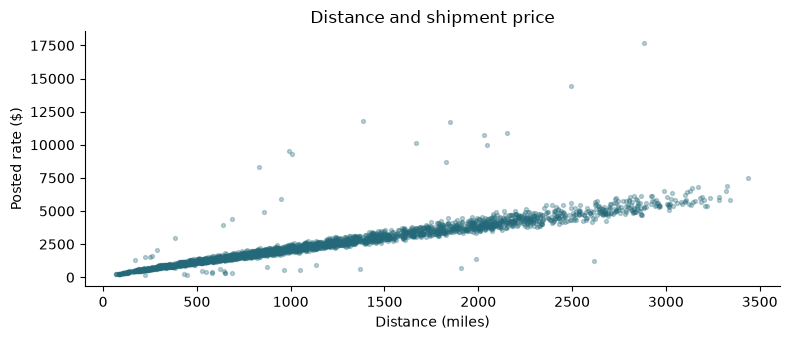

,distance,count,median
0,<=200,1686,2.80
1,200-300,2297,2.59
2,300-450,4713,2.42
3,450-600,4731,2.30
4,600-1000,11918,2.17
5,>1000,22655,2.00


,distance,count,median
0,<=200,1686,2.80
1,200-300,2297,2.59
2,300-450,4713,2.42
3,450-600,4731,2.30
4,600-1000,11918,2.17
5,>1000,22655,2.00


In [3]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(df.posted_rate, bins=80, color="#246979")
ax.set(title="Shipment prices have a long upper tail", xlabel="Posted rate ($)", ylabel="Loads")
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(8, 3.5))
sample = df.sample(min(3000, len(df)), random_state=42)
ax.scatter(sample.distance, sample.posted_rate, s=8, alpha=.3, color="#246979")
ax.set(title="Distance and shipment price", xlabel="Distance (miles)", ylabel="Posted rate ($)")
plt.tight_layout(); plt.show()
show_table("training_rpm_groups")

The histogram shows the upper tail; the scatterplot shows an association, not a causal explanation.
Price and distance have correlation **0.91**. [Source: training_summary.json]
The distance-group table shows higher median rate per mile for shorter trips.
Distance therefore remains a model feature even though the target is normalized by distance.

## Weight problems and cleaning decisions

I compare absolute negative weights with positive weights before choosing a correction.
Missing values remain NaN, which means an absent numeric value. The model accepts
these missing values directly; no rows are deleted and no values are imputed.

In [4]:
show_table("weight_comparison")
show_table("weight_prices")
show_table("weight_equipment")
cleaned = clean_data(df)
print(json.loads((E / "cleaning_summary.json").read_text()))
assert len(cleaned) == len(df)
assert cleaned.weight.isna().equals(df.weight.isna())
assert cleaned.market_index.isna().equals(df.market_index.isna())
print("No deletion, no imputation, and shared cleaning checks: PASS")

,Unnamed: 0,count,mean,std,min,25%,50%,75%,max
0,negative_absolute,292.0,31724.20,8262.54,5000.0,25928.5,31821.5,37284.25,47500.0
1,positive,47408.0,31415.36,7994.90,5000.0,25922.0,31493.5,37063.00,47500.0


,negative,count,median
0,False,47708,2.15
1,True,292,2.16


,equipment,rows,negative,negative_pct
0,Dry Van,27202,155,0.57
1,Flatbed,8753,70,0.80
2,Reefer,12045,67,0.56


{'rows_before': 48000, 'rows_after': 48000, 'negative_after': 0, 'missing_weight_after': 300, 'missing_market_after': 374}
No deletion, no imputation, and shared cleaning checks: PASS


The absolute negative weights and positive weights have the same observed minimum
and maximum, but their means and medians are similar rather than identical. [Source: weight_comparison.csv]
This looks like a sign error; it is an inference, not proof. I take the absolute value
and retain `weight_was_negative`, while separate flags retain missingness information.

## The quote signal finding

I compare daily correlation between `quote_signal` and `log(distance)` with the
month-by-distance median tables. The labels describe an observed distance pattern;
they do not prove that a quote equals the actual shipment rate.

In [5]:
print({"follows_price_if_correlation_below": -0.5, "upside_down_if_above": 0.5,
       "otherwise": "flat"})
show_table("training_behaviour")
show_table("training_correlation_ranges")
show_table("training_quote_medians")
show_table("training_rpm_medians")

{'follows_price_if_correlation_below': -0.5, 'upside_down_if_above': 0.5, 'otherwise': 'flat'}


,date,flat,follows price,upside down
0,2025-01,0,31,0
1,2025-02,0,28,0
2,2025-03,0,31,0
3,2025-04,0,0,30
4,2025-05,0,0,31
5,2025-06,0,30,0
6,2025-07,0,0,31
7,2025-08,31,0,0
8,2025-09,0,30,0
9,2025-10,0,0,31


,behaviour,min,max,count
0,flat,-0.11,0.15,31
1,follows price,-0.89,-0.72,150
2,upside down,0.70,0.88,123


,date,<=200,200-300,300-450,450-600,600-1000,>1000
0,2025-01,2.64,2.46,2.29,2.18,2.05,1.90
1,2025-02,2.73,2.47,2.33,2.20,2.10,1.93
2,2025-03,2.76,2.61,2.42,2.29,2.17,1.99
3,2025-04,1.37,1.57,1.71,1.84,1.97,2.14
4,2025-05,1.31,1.48,1.67,1.79,1.94,2.10
5,2025-06,2.93,2.71,2.52,2.40,2.28,2.09
6,2025-07,1.32,1.52,1.70,1.81,1.94,2.10
7,2025-08,2.04,2.06,2.05,2.04,2.04,2.06
8,2025-09,2.85,2.61,2.45,2.32,2.20,2.00
9,2025-10,1.35,1.53,1.71,1.84,1.95,2.13


,date,<=200,200-300,300-450,450-600,600-1000,>1000
0,2025-01,2.64,2.46,2.29,2.18,2.05,1.90
1,2025-02,2.73,2.48,2.32,2.20,2.10,1.92
2,2025-03,2.76,2.62,2.42,2.29,2.16,1.99
3,2025-04,2.78,2.58,2.43,2.32,2.17,2.01
4,2025-05,2.84,2.68,2.48,2.36,2.21,2.05
5,2025-06,2.94,2.71,2.52,2.41,2.28,2.09
6,2025-07,2.84,2.64,2.45,2.35,2.21,2.05
7,2025-08,2.77,2.54,2.36,2.29,2.15,1.98
8,2025-09,2.86,2.62,2.45,2.31,2.19,2.01
9,2025-10,2.81,2.62,2.46,2.30,2.20,2.02


,date,<=200,200-300,300-450,450-600,600-1000,>1000
0,2025-01,2.64,2.46,2.29,2.18,2.05,1.90
1,2025-02,2.73,2.48,2.32,2.20,2.10,1.92
2,2025-03,2.76,2.62,2.42,2.29,2.16,1.99
3,2025-04,2.78,2.58,2.43,2.32,2.17,2.01
4,2025-05,2.84,2.68,2.48,2.36,2.21,2.05
5,2025-06,2.94,2.71,2.52,2.41,2.28,2.09
6,2025-07,2.84,2.64,2.45,2.35,2.21,2.05
7,2025-08,2.77,2.54,2.36,2.29,2.15,1.98
8,2025-09,2.86,2.62,2.45,2.31,2.19,2.01
9,2025-10,2.81,2.62,2.46,2.30,2.20,2.02


- Negative daily correlations are labelled **follows price**, positive ones **upside down**, and those between the thresholds **flat**. The names are descriptive labels. [Source: src/features.py, daily_behaviour]
- The tables show decreasing quote medians with distance in the follows-price months, the opposite pattern in upside-down months, and nearly equal medians in the flat month. Actual median rates per mile decrease with distance across the printed months. [Source: training_quote_medians.csv; training_rpm_medians.csv]
- I exclude `quote_signal` and its derived inputs from the final model. They remain in a comparison model only.

## Checking validation.csv

This is the first external-data load in this notebook. I check the schema, IDs,
template order, missing values, unseen cities, and daily quote behaviour using
features only; this file has no observed prices.

In [6]:
validation = check_external(df)
print("shape:", validation.shape)
display(validation.head())

external_behaviour


behaviour  flat
date           
2025-11      30
2025-12      31



external_quote_medians
distance  <=200  200-300  300-450  450-600  600-1000  >1000
date                                                       
2025-11    2.07     2.06     2.05     2.04      2.05   2.07
2025-12    2.04     2.02     2.05     2.05      2.05   2.05

external_correlation_ranges
            min   max  count
behaviour                   
flat      -0.17  0.21     61

{
  "rows": 12000,
  "columns": 13,
  "start": "2025-11-01",
  "end": "2025-12-31",
  "duplicate_rows": 0,
  "duplicate_ids": 0,
  "missing_weight": 165,
  "negative_weight": 145,
  "missing_market_index": 249,
  "nonpositive_distance": 0,
  "same_schema_without_target": true,
  "template_same_ids": true,
  "template_same_order": true,
  "unseen_cities": [
    "Allentown",
    "Charlotte",
    "Chicago",
    "Jackson",
    "Knoxville",
    "Laredo",
    "Norfolk",
    "San Diego"
  ],
  "unseen_city_count": 8,
  "affected_loads": 1447,
  "affected_pct": 12.06,
  "flat_days": 61,
  "days": 61
}
external_missing
  

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal
0,TE-000001,Baton Rouge,Mobile,30.50134,-92.65374,31.80442,-88.25195,331.4,Flatbed,19958.0,2025-11-01,0.90402,1.86388
1,TE-000002,Savannah,Los Angeles,33.60973,-82.29994,28.56624,-116.70249,2406.2,Reefer,34114.0,2025-11-01,0.92851,1.86240
2,TE-000003,San Francisco,Raleigh,35.19670,-121.69849,35.37376,-77.47605,2846.6,Dry Van,33435.0,2025-11-01,0.88117,1.95480
3,TE-000004,Dayton,Los Angeles,39.87206,-85.62931,28.56624,-116.70249,2261.6,Dry Van,25392.0,2025-11-01,0.89156,2.14579
4,TE-000005,Memphis,San Antonio,35.56802,-89.52871,29.50969,-98.40059,800.4,Flatbed,NaN,2025-11-01,0.88308,2.22541


- The file contains **12,000 loads**, from **2025-11-01** through **2025-12-31**. The ID set and order match the template. [Source: external_summary.json]
- **8 cities** are absent from the labeled data, affecting **1,447 loads (12.06%)**. The printed list identifies them. [Source: external_summary.json]
- All **61 days** are classified as flat. This means weak observed daily distance association, not proof of zero information about every possible target. [Source: external_summary.json; external_correlation_ranges.csv]

I use coordinates rather than city labels. The later hidden-city experiment checks
this choice on labeled development data without claiming that unseen cities never hurt.

## Time split and validation approach

I train on earlier months and evaluate later months because this task predicts a
later period. A fold is one train/evaluation pair; each monthly fold expands the
training window. Starting in April gives the first fold the preceding quarter of
history; starting earlier would provide less history under this design.

In [7]:
split_summary(df)
cv = show_table("cv_folds")
display(cv.loc[cv.model.eq("LightGBM final"), ["month", "train_rows", "validation_rows"]])
print(json.loads((E / "holdout_ledger.json").read_text()))

split
              rows       start         end
split                                     
Development  38477  2025-01-01  2025-08-31
Test          9523  2025-09-01  2025-10-31



,model,month,train_rows,validation_rows,MAE,MAPE,RMSE,R2
0,Quote reference,2025-04,14291,4819,403.31,20.10,723.26,0.76
1,Quote reference,2025-05,19110,4913,403.40,21.00,730.65,0.76
2,Quote reference,2025-06,24023,4783,82.85,2.81,695.13,0.81
3,Quote reference,2025-07,28806,4912,415.77,20.68,792.28,0.72
4,Quote reference,2025-08,33718,4759,317.26,14.74,712.25,0.77
5,Median RPM,2025-04,14291,4819,222.23,11.33,577.67,0.84
6,Median RPM,2025-05,19110,4913,224.23,11.54,605.10,0.83
7,Median RPM,2025-06,24023,4783,257.30,11.96,732.64,0.79
8,Median RPM,2025-07,28806,4912,241.65,10.94,678.17,0.80
9,Median RPM,2025-08,33718,4759,260.52,11.46,673.96,0.79


,month,train_rows,validation_rows
20,2025-04,14291,4819
21,2025-05,19110,4913
22,2025-06,24023,4783
23,2025-07,28806,4912
24,2025-08,33718,4759


{'choice_sha256': '32e69c889e6fadf10b74f6a72292619aa3ba39d704511259cb8e888374002f6b', 'started_at_utc': '2026-10-07T09:02:13.398290+00:00', 'new_pipeline_evaluation_count': 1, 'prior_exposure': 'An older executed checkpoint scored Ridge and Log-target Ridge on September-October. The original notebook supplied for finalization explored those months but did not score a holdout model. All current LightGBM choices use January-August folds only.', 'completed_at_utc': '2026-10-07T09:02:15.567583+00:00', 'prior_exposure_source': 'reports/evidence/prior_holdout_exposure.json'}


Development uses January-August and the final test uses September-October. [Source: split.csv]
The expanding folds cover April-August; their behaviour labels are upside down,
upside down, follows price, upside down, and flat. [Source: cv_folds.csv; training_behaviour.csv]
August is the closer check for the external file's quote behaviour, although that
does not establish that all other data properties match.

**Test exposure:** the current LightGBM pipeline scores the test once after locking
choices. Earlier Ridge work in this project already scored the same months, and
the original notebook explored their labels; this is not a historically untouched
    test set. No current LightGBM choice uses those earlier scores. The saved checkpoint
    identifies both Ridge and log-target Ridge; the original notebook supplied for
    finalization explored the test months but did not score a holdout model.
    [Source: holdout_ledger.json; prior_holdout_exposure.json]

## Features and model

A feature is one input column. The final inputs describe distance, weight, equipment,
coordinates, market index, and missingness or invalidity flags. LightGBM fits decision
trees with missing-value handling, and the pipeline applies no scaling.

The target is rate per mile, and Huber is the selected loss function for reducing
sensitivity to large residuals. This is a modeling choice, not proof that extreme
prices are incorrect. No feature is built from another load's price.

In [8]:
features = build_features(df)
print("Feature count:", len(FEATURES))
print("Feature list:", FEATURES)
print("Missing values retained:", features.isna().sum().loc[lambda x: x > 0].to_dict())
assert features.columns.tolist() == FEATURES
assert not any("quote" in c or "qs" in c for c in FEATURES)
print("Shared src.features.build_features is used in notebook and prediction: PASS")
print(json.loads((ROOT / "models/final_settings.json").read_text()))

Feature count: 13
Feature list: ['distance', 'weight', 'weight_missing', 'weight_was_negative', 'eq_DryVan', 'eq_Flatbed', 'eq_Reefer', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'market_index', 'market_index_missing']
Missing values retained: {'weight': 300, 'market_index': 374}
Shared src.features.build_features is used in notebook and prediction: PASS
{'objective': 'huber', 'alpha': 0.5, 'n_estimators': 600, 'learning_rate': 0.03, 'num_leaves': 31, 'min_child_samples': 40, 'subsample': 0.8, 'subsample_freq': 1, 'colsample_bytree': 0.8, 'random_state': 42, 'verbosity': -1, 'n_jobs': 2}


## Expanding window comparison

MAE is average absolute error in dollars. MAPE is average absolute percentage error.
RMSE gives extra weight to large dollar errors; R2 compares squared error with
predicting the evaluation set's mean. The mean scores below weight each fold equally.

The recorded comparisons were generated by `src.evaluate.compare_models`, which
calls `src.train.cross_validate`. The quote comparison uses same-day batches of
input quotes; it does not use future prices and is not deployed.

In [9]:
summary = show_table("cv_summary")
display(cv.pivot(index="model", columns="month", values="MAE").round(2))
display(cv.pivot(index="model", columns="month", values="MAPE").round(2))

,model,MAE,MAPE,RMSE,R2
0,Quote reference,324.52,15.87,730.71,0.76
1,Median RPM,241.19,11.45,653.51,0.81
2,LightGBM with quote,147.91,6.93,628.33,0.83
3,LightGBM core,142.32,5.99,618.20,0.83
4,LightGBM final,108.12,4.71,607.94,0.84


month,2025-04,2025-05,2025-06,2025-07,2025-08
model,,,,,
LightGBM core,125.43,157.34,210.86,122.53,95.45
LightGBM final,98.36,91.98,142.76,97.56,109.93
LightGBM with quote,312.78,82.33,104.78,83.96,155.70
Median RPM,222.23,224.23,257.30,241.65,260.52
Quote reference,403.31,403.40,82.85,415.77,317.26


month,2025-04,2025-05,2025-06,2025-07,2025-08
model,,,,,
LightGBM core,5.94,6.94,7.81,4.87,4.41
LightGBM final,4.96,4.48,5.20,3.93,4.97
LightGBM with quote,15.69,4.13,3.69,3.39,7.75
Median RPM,11.33,11.54,11.96,10.94,11.46
Quote reference,20.10,21.00,2.81,20.68,14.74


The default model with market index has the lowest mean MAE among the comparison
models. August alone favors the core model without market index over that default,
so the average result does not imply a win in every month. [Source: cv_folds.csv; cv_summary.csv]

## Small development-only tuning check

A small search limits the risk of fitting noise in the available validation months.
Each change is tested separately using fixed seeds; untested combinations are not
selected. The table records every trial, including rejected features.

In [10]:
show_table("tuning")
print(json.loads((ROOT / "models/selection.json").read_text()))
selected = show_table("selected_cv_folds")
print("Selected fold mean:", selected[["MAE", "MAPE", "RMSE", "R2"]].mean().round(2).to_dict())

,trial,changes,extra,mean_MAE,august_MAE,improvement_pct,eligible,selected
0,default,{},NaN,108.16,109.97,0.00,False,False
1,alpha_0.5,"{""alpha"": 0.5}",NaN,104.94,109.16,2.98,True,True
2,alpha_2,"{""alpha"": 2.0}",NaN,112.84,109.05,-4.32,False,False
3,leaves_15,"{""num_leaves"": 15}",NaN,106.50,109.52,1.53,True,False
4,min_child_80,"{""min_child_samples"": 80}",NaN,107.50,109.69,0.61,False,False
5,circuity,{},circuity,107.98,110.01,0.16,False,False
6,weekday,{},weekday,111.50,114.38,-3.09,False,False
7,log_distance,{},log_distance,107.97,109.79,0.17,False,False


{'params': {'objective': 'huber', 'alpha': 0.5, 'n_estimators': 600, 'learning_rate': 0.03, 'num_leaves': 31, 'min_child_samples': 40, 'subsample': 0.8, 'subsample_freq': 1, 'colsample_bytree': 0.8, 'random_state': 42, 'verbosity': -1, 'n_jobs': 2}, 'features': ['distance', 'weight', 'weight_missing', 'weight_was_negative', 'eq_DryVan', 'eq_Flatbed', 'eq_Reefer', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'market_index', 'market_index_missing'], 'selected_trial': 'alpha_0.5', 'seeds': [42, 43], 'policy': 'Mean MAE improvement greater than 1%; extra features must not worsen August. No untested combinations.', 'locked_at_utc': '2026-10-07T09:02:04.336435+00:00'}


,month,train_rows,validation_rows,MAE,MAPE,RMSE,R2
0,2025-04,14291,4819,94.68,4.78,523.34,0.87
1,2025-05,19110,4913,85.26,4.20,554.83,0.86
2,2025-06,24023,4783,140.50,5.11,709.83,0.80
3,2025-07,28806,4912,95.28,3.84,627.43,0.83
4,2025-08,33718,4759,109.26,4.93,620.67,0.82


Selected fold mean: {'MAE': 104.99, 'MAPE': 4.57, 'RMSE': 607.22, 'R2': 0.84}


The chosen change is **alpha = 0.5**, with **2.98%** lower mean MAE than default across the tuning seeds. [Source: tuning.csv]
The rule required more than **1%** mean improvement; an extra feature also had to
avoid worsening August. [Source: models/selection.json]
Circuity, weekday, and log distance did not pass. The final list remains **13 features**. [Source: tuning.csv; models/features.json]
Seed **42** is used for production and the hidden-city draw; seed **43** is used only
for the requested second-seed tuning check. [Source: models/selection.json; src/evaluate.py]

## Hidden-city check

The paired experiment uses the same August evaluation loads. One model sees all
earlier training cities; another excludes all earlier loads touching the randomly
selected hidden cities. This checks sensitivity to those cities and the reduced
training data together, so it is not a guarantee for new cities.

In [11]:
print("Hidden cities:", json.loads((E / "hidden_cities.json").read_text()))
show_table("unseen_city_test")

Hidden cities: ['Bakersfield', 'Hartford', 'Memphis', 'New York', 'San Antonio', 'Toledo', 'Tulsa', 'Washington']


,condition,train_rows,evaluation_rows,MAE,MAPE,RMSE,R2
0,Cities seen in training,33718,1226,95.59,4.03,385.87,0.92
1,Cities hidden from training,24898,1226,95.69,4.06,386.88,0.92


,condition,train_rows,evaluation_rows,MAE,MAPE,RMSE,R2
0,Cities seen in training,33718,1226,95.59,4.03,385.87,0.92
1,Cities hidden from training,24898,1226,95.69,4.06,386.88,0.92


The displayed errors are close in this particular draw. This supports using the
coordinate model here, but does not establish that unseen locations never hurt.
[Source: unseen_city_test.csv]

## Final test evaluation

These stored results come from the guarded evaluation after settings were locked.
The notebook displays the saved results rather than scoring this test again.
September and October have follows-price and upside-down quote behaviour; neither
has the flat pattern of the external period. [Source: training_behaviour.csv; external_behaviour.csv]

In [12]:
test = pd.read_csv(E / "holdout_metrics.csv")
for grouping in ["overall", "month", "equipment", "distance"]:
    print(grouping)
    display(test.loc[test.grouping.eq(grouping)].round(2))

overall


,model,grouping,group,rows,MAE,MAPE,RMSE,R2
0,Selected LightGBM,overall,all,9523,160.21,6.78,648.41,0.82
12,Quote reference,overall,all,9523,246.02,12.11,711.80,0.78
24,Median RPM,overall,all,9523,256.95,11.63,684.25,0.80


month


,model,grouping,group,rows,MAE,MAPE,RMSE,R2
1,Selected LightGBM,month,2025-09,4670,167.45,6.76,635.06,0.83
2,Selected LightGBM,month,2025-10,4853,153.25,6.81,661.00,0.81
13,Quote reference,month,2025-09,4670,71.75,2.88,609.41,0.84
14,Quote reference,month,2025-10,4853,413.72,20.99,798.02,0.73
25,Median RPM,month,2025-09,4670,260.83,11.45,673.30,0.80
26,Median RPM,month,2025-10,4853,253.22,11.81,694.62,0.79


equipment


,model,grouping,group,rows,MAE,MAPE,RMSE,R2
3,Selected LightGBM,equipment,Dry Van,5360,151.95,6.38,667.97,0.79
4,Selected LightGBM,equipment,Flatbed,1770,168.47,7.56,529.10,0.88
5,Selected LightGBM,equipment,Reefer,2393,172.62,7.12,683.14,0.82
15,Quote reference,equipment,Dry Van,5360,244.97,11.15,738.99,0.75
16,Quote reference,equipment,Flatbed,1770,210.21,12.28,566.91,0.86
17,Quote reference,equipment,Reefer,2393,274.87,14.15,745.20,0.79
27,Median RPM,equipment,Dry Van,5360,288.55,11.50,721.98,0.76
28,Median RPM,equipment,Flatbed,1770,198.49,11.02,537.91,0.87
29,Median RPM,equipment,Reefer,2393,229.42,12.38,694.00,0.82


distance


,model,grouping,group,rows,MAE,MAPE,RMSE,R2
6,Selected LightGBM,distance,<=200,341,22.54,5.28,89.30,0.58
7,Selected LightGBM,distance,200-300,439,41.95,8.08,119.84,0.28
8,Selected LightGBM,distance,300-450,967,74.07,7.33,283.37,0.08
9,Selected LightGBM,distance,450-600,977,84.68,6.52,320.24,0.10
10,Selected LightGBM,distance,600-1000,2338,115.82,7.06,391.78,0.27
11,Selected LightGBM,distance,>1000,4461,240.86,6.57,880.44,0.57
18,Quote reference,distance,<=200,341,113.77,28.69,182.36,-0.76
19,Quote reference,distance,200-300,439,148.20,22.71,234.91,-1.78
20,Quote reference,distance,300-450,967,184.36,18.87,364.19,-0.53
21,Quote reference,distance,450-600,977,165.98,12.89,394.96,-0.37


The selected model has test **MAE $160.21**, **MAPE 6.78%**,
**RMSE $648.41**, and **R2 0.82**. [Source: holdout_metrics.csv, overall Selected LightGBM]
    These are test-period estimates, distinct from the development folds.
    The test error is higher than mean development MAE **$104.99**.
    The cause was not investigated; the true error on the final prediction period
    could also exceed that development average. Settings and features were not
    changed after this evaluation. [Source: selected_cv_folds.csv; holdout_metrics.csv]

## Final refit and prediction checks

The locked model is refitted on all labeled data. Predictions are merged by load ID
into the template order. The saved model, feature list, output checks, and scorer log
are regenerated by the same `src.run.run_final` function used from the command line.

In [13]:
prediction_summary = run_final()
print(json.dumps(prediction_summary, indent=2))
show_table("rpm_sanity")
show_table("unseen_predictions")

Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: scorer_results\candidate_december.png
Final validation metrics are calculated by Spotter after submission.



{
  "training_rows": 48000,
  "prediction_rows": 12000,
  "prediction_missing": 0,
  "prediction_min": 183.66,
  "prediction_max": 6693.88,
  "floors": 0,
  "december_rows": 31,
  "december_min": 802.49,
  "december_max": 818.45,
  "december_floors": 0,
  "comparable_rows": 2020,
  "comparable_median": 833.97,
  "comparable_q25": 783.76,
  "comparable_q75": 897.44,
  "comparable_monthly_median_min": 791.74,
  "comparable_monthly_median_max": 872.38,
  "varying_december_features": [
    "market_index"
  ],
  "scorer_sha256": "f73af4f34acf0c43cdd6e2cd6b2c0ec8b9da4420fd6fdcd69bd86e14d4868634"
}


{
  "training_rows": 48000,
  "prediction_rows": 12000,
  "prediction_missing": 0,
  "prediction_min": 183.66,
  "prediction_max": 6693.88,
  "floors": 0,
  "december_rows": 31,
  "december_min": 802.49,
  "december_max": 818.45,
  "december_floors": 0,
  "comparable_rows": 2020,
  "comparable_median": 833.97,
  "comparable_q25": 783.76,
  "comparable_q75": 897.44,
  "comparable_monthly_median_min": 791.74,
  "comparable_monthly_median_max": 872.38,
  "varying_december_features": [
    "market_index"
  ],
  "scorer_sha256": "f73af4f34acf0c43cdd6e2cd6b2c0ec8b9da4420fd6fdcd69bd86e14d4868634"
}


,distance,training_median_rpm,prediction_median_rpm
0,<=200,2.80,2.74
1,200-300,2.59,2.55
2,300-450,2.42,2.38
3,450-600,2.30,2.25
4,600-1000,2.17,2.13
5,>1000,2.00,1.96


,unseen_city,rows,minimum,median,maximum
0,False,10553,188.99,1992.32,6693.88
1,True,1447,183.66,2013.48,6487.11


,unseen_city,rows,minimum,median,maximum
0,False,10553,188.99,1992.32,6693.88
1,True,1447,183.66,2013.48,6487.11


The output has **12,000 rows** with **0 missing values**;
predictions range from **$183.66** to **$6693.88**.
A positive-rate floor was needed for **0 rows**. [Source: prediction_summary.json]
The group medians decrease with distance in both the training rates and final
predictions. The unseen-city table is an output sanity check, not an accuracy
measurement, because external prices are absent. [Source: rpm_sanity.csv; unseen_predictions.csv]

## Final model feature importance

Gain measures how much a feature reduced the training objective when a tree split
used it. It describes model use, not causal influence or performance on unseen data.

,feature,gain,splits,gain_pct
0,distance,25238.81,3232,57.05
1,eq_DryVan,7031.23,564,15.89
2,delivery_lon,2845.37,1992,6.43
3,weight,2038.97,2987,4.61
4,market_index,1715.29,2967,3.88
5,pickup_lon,1703.93,1914,3.85
6,eq_Reefer,1294.93,355,2.93
7,pickup_lat,1235.22,1864,2.79
8,delivery_lat,788.30,1898,1.78
9,eq_Flatbed,343.29,209,0.78


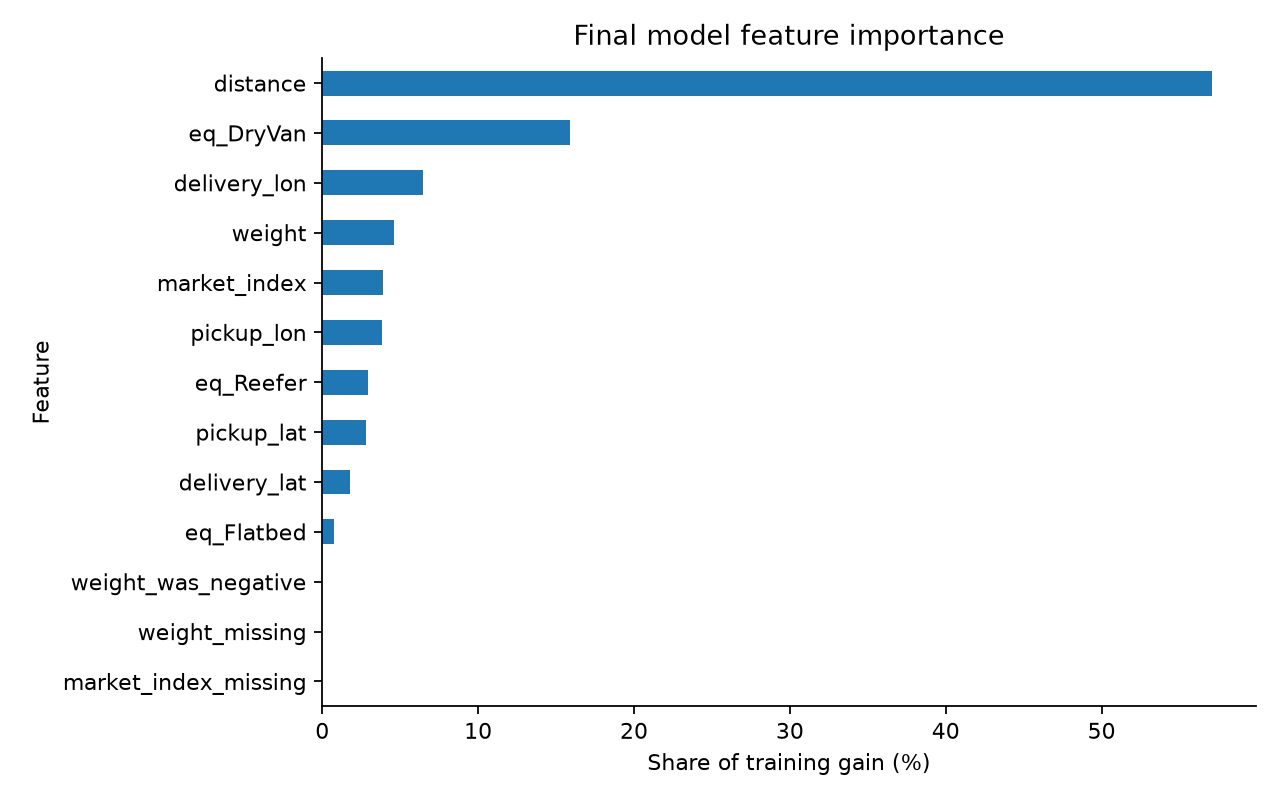

In [14]:
show_table("feature_importance")
display(Image(filename=str(E / "feature_importance.png")))

Distance has the largest recorded share of gain. Equipment, coordinates, weight,
and market index also contribute. The gain chart describes the final refit.
[Source: feature_importance.csv]

## December prediction chart

The original December file is backed up. Coordinates come from the labeled city
lookup, and the market index is the median observed external index for each date.
The file's other values, column order, and date strings are preserved.

,pickup,delivery,distance,equipment,weight,date,predicted_rate,pickup_lat,pickup_lon,delivery_lat,delivery_lon,market_index
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,802.49,36.99,-85.0,41.32,-85.36,0.83
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,808.15,36.99,-85.0,41.32,-85.36,0.91
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,814.47,36.99,-85.0,41.32,-85.36,0.99
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,817.90,36.99,-85.0,41.32,-85.36,1.03
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,813.17,36.99,-85.0,41.32,-85.36,0.97
5,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-06,806.67,36.99,-85.0,41.32,-85.36,0.89
6,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-07,802.57,36.99,-85.0,41.32,-85.36,0.83
7,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-08,803.73,36.99,-85.0,41.32,-85.36,0.84
8,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-09,808.15,36.99,-85.0,41.32,-85.36,0.92
9,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-10,815.50,36.99,-85.0,41.32,-85.36,1.00


,date,median_dollars
0,2025-01,791.74
1,2025-02,805.80
2,2025-03,831.98
3,2025-04,841.31
4,2025-05,855.59
5,2025-06,872.38
6,2025-07,839.54
7,2025-08,836.07
8,2025-09,830.98
9,2025-10,841.76


,date,weekday,market_index,predicted_rate
0,2025-12-01,Monday,0.83,802.49
1,2025-12-02,Tuesday,0.91,808.15
2,2025-12-03,Wednesday,0.99,814.47
3,2025-12-04,Thursday,1.03,817.90
4,2025-12-05,Friday,0.97,813.17
5,2025-12-06,Saturday,0.89,806.67
6,2025-12-07,Sunday,0.83,802.57
7,2025-12-08,Monday,0.84,803.73
8,2025-12-09,Tuesday,0.92,808.15
9,2025-12-10,Wednesday,1.00,815.50


,weekday,days,mean_market_index,mean_predicted_rate
0,Monday,5,0.85,805.01
1,Tuesday,5,0.93,808.23
2,Wednesday,5,1.01,816.13
3,Thursday,4,1.03,818.07
4,Friday,4,0.99,813.87
5,Saturday,4,0.90,807.17
6,Sunday,4,0.84,804.65


{'training_rows': 48000, 'prediction_rows': 12000, 'prediction_missing': 0, 'prediction_min': 183.66, 'prediction_max': 6693.88, 'floors': 0, 'december_rows': 31, 'december_min': 802.49, 'december_max': 818.45, 'december_floors': 0, 'comparable_rows': 2020, 'comparable_median': 833.97, 'comparable_q25': 783.76, 'comparable_q75': 897.44, 'comparable_monthly_median_min': 791.74, 'comparable_monthly_median_max': 872.38, 'varying_december_features': ['market_index'], 'scorer_sha256': 'f73af4f34acf0c43cdd6e2cd6b2c0ec8b9da4420fd6fdcd69bd86e14d4868634'}
Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: scorer_results\candidate_december.png
Final validation metrics are calculated by Spotter after submission.



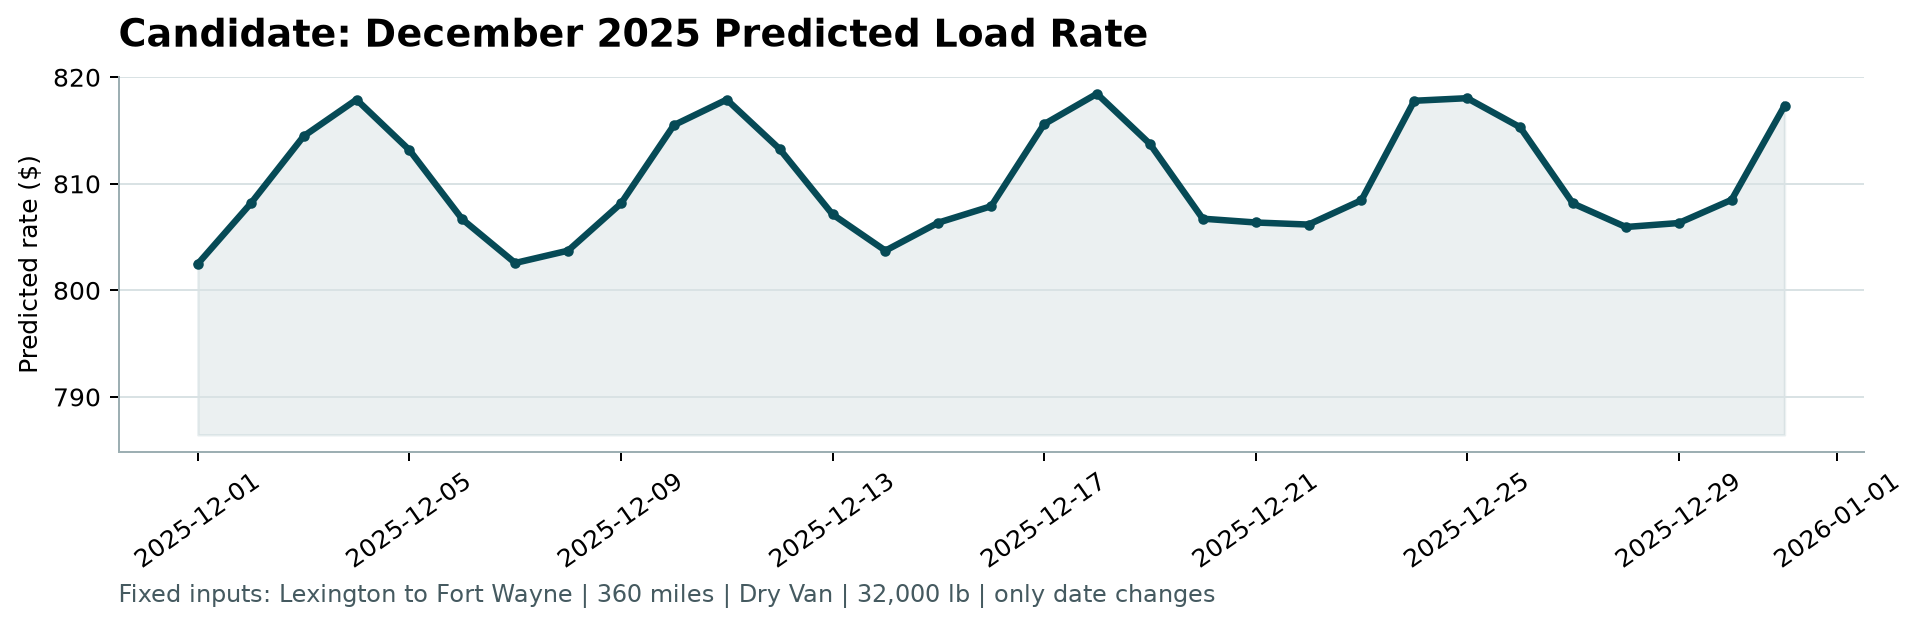

In [15]:
show_table("december_augmented")
show_table("comparable_monthly_medians")
show_table("december_daily_pattern")
show_table("december_weekday_pattern")
print(json.loads((E / "prediction_summary.json").read_text()))
print((E / "scorer_log.txt").read_text())
display(Image(filename=str(ROOT / "scorer_results/candidate_december.png")))

The scorer-generated line spans **$802.49 to $818.45**,
so its movement is modest relative to its price level. Only `market_index` changes
among model inputs; the date selects that daily value. [Source: prediction_summary.json]
For comparable Dry Van shipments, the observed monthly median price spans
**$791.74 to $872.38**.
    The comparison is descriptive and does not establish the true December price.
    [Source: comparable_monthly_medians.csv]

    The weekday averages rise toward Thursday and fall toward Sunday. The pattern
    comes through the daily median market index from the December loads in
    `validation.csv`; no cause for the index's behaviour is established here.
    [Source: december_weekday_pattern.csv; december_daily_pattern.csv]

## Limitations

August is the only flat-behaviour labeled month, and the hidden-city test uses one
fixed random draw. The actual external prices and assessors' metric are unavailable.
The chart's daily variation depends solely on its daily market-index input.
[Source: training_behaviour.csv; hidden_cities.json; data/validation.csv; score.py; prediction_summary.json]

The sign-error treatment is an assumption. Market-index availability at quote time
also remains an assumption; the batch December calculation uses all provided loads
on each date. Historical test exposure is recorded in the evaluation ledger.
[Source: src/features.py; src/run.py; holdout_ledger.json]